# Лабораторная работа № 4. Цены квартир в Якутске

Применяем подход из примера Boston Housing к объявлениям о продаже квартир в Якутске. Нейросеть предсказывает полную стоимость квартиры в миллионах рублей.

In [1]:
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
EPOCHS = 100
BATCH_SIZE = 16

data_dir = Path("data")
if not (data_dir / "yakutsk_housing.csv").is_file():
    data_dir = Path("ArtificialIntelligence/laba4/data")

## Данные

Объединяем объявления с районами и показателями инфраструктуры. После удаления повторов откладываем 20% объявлений для итоговой проверки.

In [2]:
housing = pd.read_csv(
    data_dir / "yakutsk_housing.csv",
    usecols=[
        "listing_id", "price_rub", "area_m2", "rooms", "floor",
        "floors_total", "wall_material", "building_year", "living_area_m2",
        "is_first_floor", "is_last_floor", "floor_ratio",
    ],
)
districts = pd.read_csv(
    data_dir / "yakutsk_housing_location_audit.csv",
    usecols=["listing_id", "assigned_district"],
).rename(columns={"assigned_district": "district"})
infrastructure = pd.read_csv(
    data_dir / "yakutsk_district_infrastructure.csv",
).drop(columns="source_url")

data = (
    housing.merge(districts, on="listing_id", validate="one_to_one")
    .merge(infrastructure, on="district", validate="many_to_one")
    .drop(columns="listing_id")
    .drop_duplicates()
)
data = data.loc[data["price_rub"] > 0]

X = data.drop(columns="price_rub")
y = data["price_rub"].to_numpy(dtype="float32") / 1_000_000
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()
X[categorical_columns] = X[categorical_columns].astype(object).fillna(np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED,
)
print(f"Всего объявлений {len(X)} · обучение {len(X_train)} · тест {len(X_test)}")

Всего объявлений 391 · обучение 312 · тест 79


## Модель и перекрёстная проверка

Подготовку признаков и нейросеть с двумя слоями по 64 нейрона обучаем заново на каждом из четырёх фолдов. Число эпох выбираем по среднему проверочному MAE.

In [3]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


def build_model(input_size):
    model = keras.Sequential([
        keras.layers.Input(shape=(input_size,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

In [4]:
kfold = KFold(n_splits=4, shuffle=True, random_state=SEED)
histories = []

for fold, (fit_idx, val_idx) in enumerate(kfold.split(X_train), start=1):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED + fold)

    preprocessor = make_preprocessor()
    fold_train = preprocessor.fit_transform(X_train.iloc[fit_idx]).astype("float32")
    fold_val = preprocessor.transform(X_train.iloc[val_idx]).astype("float32")

    model = build_model(fold_train.shape[1])
    history = model.fit(
        fold_train, y_train[fit_idx],
        validation_data=(fold_val, y_train[val_idx]),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
    )
    histories.append(history.history)

train_mae = np.mean([history["mae"] for history in histories], axis=0)
val_mae = np.mean([history["val_mae"] for history in histories], axis=0)
best_epoch = int(np.argmin(val_mae)) + 1

print(f"Эпоха {best_epoch} · проверочный MAE {val_mae[best_epoch - 1]:.3f} млн руб.")

Эпоха 47 · проверочный MAE 1.086 млн руб.


## Итог на отложенном тесте

Обучаем модель на всей обучающей выборке до выбранной эпохи. Для сравнения используем медиану цен из обучающей выборки.

In [5]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

preprocessor = make_preprocessor()
train_ready = preprocessor.fit_transform(X_train).astype("float32")
test_ready = preprocessor.transform(X_test).astype("float32")

model = build_model(train_ready.shape[1])
model.fit(train_ready, y_train, epochs=best_epoch, batch_size=BATCH_SIZE, verbose=0)
y_pred = model.predict(test_ready, verbose=0).ravel()
baseline = np.full_like(y_test, np.median(y_train))

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
baseline_mae = mean_absolute_error(y_test, baseline)

print(f"Нейросеть · MAE {test_mae:.3f} млн руб. · RMSE {test_rmse:.3f} млн руб.")
print(f"Прогноз медианой · MAE {baseline_mae:.3f} млн руб.")

Нейросеть · MAE 1.110 млн руб. · RMSE 1.374 млн руб.
Прогноз медианой · MAE 2.831 млн руб.


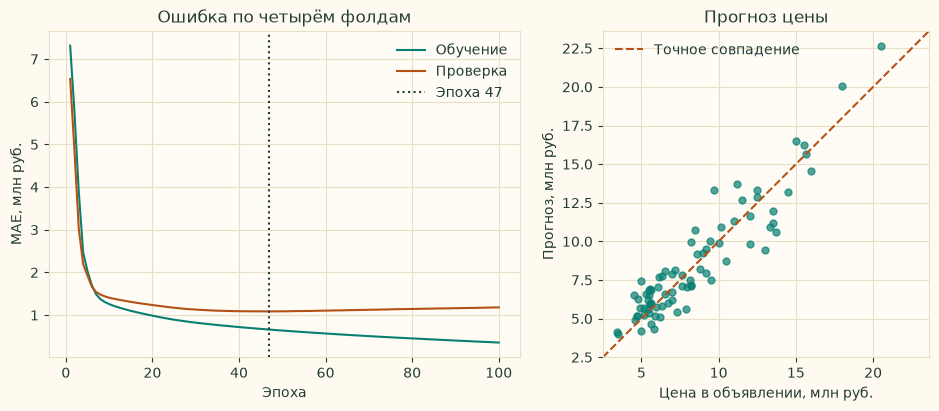

In [6]:
sea_green = "#087F73"
amber = "#B45117"
ink = "#223C36"
grid = "#E9DFC9"

fig, (ax_learning, ax_prices) = plt.subplots(
    1, 2, figsize=(10, 4), layout="constrained", facecolor="#FFFAEF",
)
for ax in (ax_learning, ax_prices):
    ax.set_facecolor("#FFFCF5")
    ax.set_axisbelow(True)
    ax.grid(color=grid)
    ax.tick_params(colors=ink)
    ax.xaxis.label.set_color(ink)
    ax.yaxis.label.set_color(ink)
    for spine in ax.spines.values():
        spine.set_color(grid)

epochs = np.arange(1, EPOCHS + 1)
ax_learning.plot(epochs, train_mae, color=sea_green, label="Обучение")
ax_learning.plot(epochs, val_mae, color=amber, label="Проверка")
ax_learning.axvline(
    best_epoch, color=ink, linestyle=":", label=f"Эпоха {best_epoch}",
)
ax_learning.set(xlabel="Эпоха", ylabel="MAE, млн руб.")
ax_learning.set_title("Ошибка по четырём фолдам", color=ink)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
padding = (upper - lower) * 0.05
bounds = (lower - padding, upper + padding)
ax_prices.plot(bounds, bounds, "--", color=amber, label="Точное совпадение")
ax_prices.scatter(y_test, y_pred, color=sea_green, s=25, alpha=0.7)
ax_prices.set(
    xlim=bounds, ylim=bounds,
    xlabel="Цена в объявлении, млн руб.", ylabel="Прогноз, млн руб.",
)
ax_prices.set_aspect("equal", adjustable="box")
ax_prices.set_title("Прогноз цены", color=ink)

for ax in (ax_learning, ax_prices):
    ax.legend(frameon=False, labelcolor=ink)
plt.show()

Расхождение кривых после выбранной эпохи указывает на переобучение. Метрики относятся к случайному разбиению этой выборки объявлений.